# Academic mobility and inbreeding-proxy analysis

This walkthrough loads mobility configuration and inputs through the mobility stage API, computes the result in memory, and displays its result tables. It does not write mobility outputs. The configured records are synthetic.

## What is being demonstrated?

Mobility links configured researcher-author selections to publication affiliations and institution metadata. It derives author-affiliation histories, publication mobility and coaffiliation measures, and an inbreeding proxy. This synthetic configuration disables university-affiliation detection, so the legacy first/last institution-overlap proxy is used. That proxy is not proof of education or training history.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

repo_root = Path.cwd()
while not (repo_root / "pyproject.toml").is_file() and repo_root != repo_root.parent:
    repo_root = repo_root.parent
if not (repo_root / "pyproject.toml").is_file():
    raise RuntimeError("Start Jupyter from within the academic-inbreeding repository.")
sys.path.insert(0, str(repo_root / "src"))

from acib.constants import AUTHOR_ID, RESEARCHER_ID, TITLE
from acib.mobility import compute_mobility, load_mobility_inputs
from acib.mobility.constants import (
    ACADEMIC_AGE_YEARS,
    AUTHOR_PROFILE_AMBIGUOUS,
    DATE_FIRST,
    DATE_LAST,
    FIRST_INST_SET,
    HAS_ANY_COAFFILIATION,
    HAS_PUBLICATION_MOBILITY,
    INBREEDING_DETECTION_METHOD,
    INBREEDING_DETECTION_STATUS,
    INBREEDING_MANUAL_REVIEW_REQUIRED,
    IS_INBREEDING_PROXY,
    LAST_INST_SET,
    N_AWAY_YEARS,
    N_COAFFILIATION_PUBLICATIONS,
    N_UNIQUE_AFFILIATIONS,
    PUBLICATION_HISTORY_YEARS,
    SHARED_INST_SET,
)
from acib.pipeline.config import load_mobility_config

## 1. Load mobility configuration

The loader resolves canonical upstream artifacts, external datasets, scientific options, and the output directory from the shared TOML. The output directory is shown for transparency; this notebook only computes and displays in-memory outputs.

In [2]:
config_path = repo_root / "config" / "pipeline_synthetic.toml"
mobility_config = load_mobility_config(config_path)

print(f"Configuration: {config_path.relative_to(repo_root)}")
print(f"Configured mobility output directory (not written): {mobility_config.outputs.directory}")
print(f"University-affiliation rule: {mobility_config.enable_university_affiliation_inbreeding_detection}")
print(f"Professor merge: {mobility_config.enable_coaffiliated_professor_merge}")
print(f"Early-affiliation method: {mobility_config.early_affiliation_method}")
print(f"Minimum publication history: {mobility_config.min_publication_history_years}")

Configuration: config/pipeline_synthetic.toml
Configured mobility output directory (not written): /home/chri/PycharmProjects/academic-inbreeding/data/output/synthetic/mobility
University-affiliation rule: False
Professor merge: True
Early-affiliation method: first_n_publications
Minimum publication history: 3


## 2. Load configured mobility inputs

The stage loader reads and validates the configured upstream researcher selections and metadata, article-author evidence, and affiliation GeoPackage. Missing external datasets or required upstream artifacts are reported by the loader; no analysis or output writing occurs in this step.

In [3]:
mobility_inputs = load_mobility_inputs(mobility_config)

print("Configured researcher-author selections:")
display(mobility_inputs.authors.head(10))
print("Configured article-author evidence:")
display(mobility_inputs.articles.head(10))
print("Configured geospatial affiliation crosswalk:")
display(mobility_inputs.affiliations.drop(
    columns=[mobility_inputs.affiliations.geometry.name], errors="ignore"
).head(10))
print(
    f"Loaded rows: selections={len(mobility_inputs.authors):,}; "
    f"articles={len(mobility_inputs.articles):,}; "
    f"affiliation features={len(mobility_inputs.affiliations):,}"
)

Configured researcher-author selections:


,sc_id,status,selected_cluster_id,selected_disambiguated_cluster_id,selected_author_ids,possible_clusters,inferred_asjc_codes,scopus_asjc_codes,inferred_asjc_labels,reason,researcher_name,person_title,university_name,current_affiliation_ids,selected_history,possible_cluster_history,person_title_class,title
0,990001,assigned_by_combined_asjc,1,990000001,"['990000002', '990000001']","[['990000002', '990000001'], ['990000003']]",[1712],[1700],['Software'],best cluster has a unique strongest assigned by combined asjc overlap,"mustermann, max",NaN,Example Technical Institute,['9901000'],{},"[{}, {}]",No Title,No Title
1,990002,assigned_single_cluster,1,990000004,"['990000004', '990000004', '990000004', '990000004']","[['990000004', '990000004', '990000004', '990000004']]",[1600],[1600],['Chemistry'],only one cluster remained after disambiguation,"do, john",Ass.-Prof. Dr.,Example Technical Institute,['9904000'],{},[{}],Ass. Prof.,Ass. Prof.
2,990004,assigned_single_cluster,1,990000005,"['990000005', '990000005', '990000005', '990000005']","[['990000005', '990000005', '990000005', '990000005']]",[1712],[1700],['Software'],only one cluster remained after disambiguation,"lovelace, ada",Univ.-Prof. Dr.,Example Technical Institute,['9901000'],{},[{}],Full Prof.,Full Prof.
3,990011,assigned_single_cluster,1,990000019,"['990000012', '990000019']","[['990000012', '990000019']]",[1712],"[1700, 2700]",['Software'],only one cluster remained after disambiguation,"morgan, casey",NaN,Example Technical Institute,"['9901000', '9906000']",{},[{}],No Title,No Title
4,990019,assigned_by_current_affiliation,1,990000020,['990000020'],"[['990000020'], ['990000021']]",[2200],[2700],['Engineering'],best cluster has a unique current-affiliation match to the researcher university,"example, ari",NaN,TU Wien,['60018163'],{},"[{}, {}]",No Title,No Title
5,990005,assigned_single_candidate,1,990000006,['990000006'],[['990000006']],[2700],[2700],['Medicine'],only one candidate author exists for this sc_id; disambiguation not required,"al hassan, noor",NaN,Example Medical Institute,['9902000'],{},[{}],No Title,No Title
6,990006,assigned_single_candidate,1,990000007,['990000007'],[['990000007']],[1200],[1200],['Arts and Humanities'],only one candidate author exists for this sc_id; disambiguation not required,"garcia, zo",NaN,Example Arts College,['9904000'],{},[{}],No Title,No Title
7,990007,assigned_single_candidate,1,990000008,['990000008'],[['990000008']],[2200],[2200],['Engineering'],only one candidate author exists for this sc_id; disambiguation not required,"martin, jean luc",NaN,Example Technical Institute,['9901000'],{},[{}],No Title,No Title
8,990008,assigned_single_candidate,1,990000009,['990000009'],[['990000009']],[2700],[2700],['Medicine'],only one candidate author exists for this sc_id; disambiguation not required,"nguyen, alice marie",NaN,Example Medical Institute,['9902000'],{},[{}],No Title,No Title
9,990009,assigned_single_candidate,1,990000010,['990000010'],[['990000010']],[1200],[1200],['Arts and Humanities'],only one candidate author exists for this sc_id; disambiguation not required,"oconnell, sami",NaN,Example Arts College,['9904000'],{},[{}],No Title,No Title


Configured article-author evidence:


,eid,author_ids,cover_date,author_afids,author_names,subject_areas,journal,city,country,synthetic_record
0,SYN-PUB-001,990000001;990010001,2021-06-15,9901001;9901001,"[""Max Mustermann"", ""Taylor Example"" ]","[{""area"":""Software"",""abbreviation"":""COMP"",""code"":1712}]",Journal of Synthetic Computing,Example City,Exampleland,True
1,SYN-PUB-002,990000002;990010001,2021-06-15,9901001;9901001,"[""M. Mustermann"", ""Taylor Example"" ]","[{""area"":""Software"",""abbreviation"":""COMP"",""code"":1712}]",Journal of Synthetic Computing,Example City,Exampleland,True
2,SYN-PUB-003,990000003;990010002,2021-06-15,9902001;9902001,"[""Max Mustermann"", ""Morgan Sample"" ]","[{""area"":""General Medicine"",""abbreviation"":""MEDI"",""code"":2700}]",Synthetic Medical Review,Sample Town,Exampleland,True
3,SYN-PUB-004,990000004;990010003,2020-06-15,9903001;9903001,"[""John Doe"", ""Casey Example"" ]","[{""area"":""Chemistry"",""abbreviation"":""CHEM"",""code"":1600}]",Journal of Fictional Chemistry,Example City,Exampleland,True
4,SYN-PUB-005,990000005;990005005,2020-06-15,9901001;9901001,"[""Ada Lovelace"", ""Colleague 990000005""]","[{""area"": ""Software"", ""abbreviation"": ""COMP"", ""code"": 1712}]",Journal of Synthetic Software,Example City,Exampleland,True
5,SYN-PUB-006,990000006;990005006,2021-06-15,9902001;9902001,"[""Noor Al-Hassan"", ""Colleague 990000006""]","[{""area"": ""General Medicine"", ""abbreviation"": ""MEDI"", ""code"": 2700}]",Journal of Synthetic General Medicine,Example City,Exampleland,True
6,SYN-PUB-007,990000007;990005007,2021-06-15,9904001;9904001,"[""Zoë García"", ""Colleague 990000007""]","[{""area"": ""Arts and Humanities"", ""abbreviation"": ""ARTS"", ""code"": 1200}]",Journal of Synthetic Arts and Humanities,Example City,Exampleland,True
7,SYN-PUB-008,990000008;990005008,2021-06-15,9901001;9901001,"[""Jean-Luc Martin"", ""Colleague 990000008""]","[{""area"": ""Engineering"", ""abbreviation"": ""ENGI"", ""code"": 2200}]",Journal of Synthetic Engineering,Example City,Exampleland,True
8,SYN-PUB-009,990000009;990005009,2021-06-15,9902001;9902001,"[""Alice M. Nguyen"", ""Colleague 990000009""]","[{""area"": ""General Medicine"", ""abbreviation"": ""MEDI"", ""code"": 2700}]",Journal of Synthetic General Medicine,Example City,Exampleland,True
9,SYN-PUB-010,990000010;990005010,2021-06-15,9904001;9904001,"[""Sami O'Connell"", ""Colleague 990000010""]","[{""area"": ""Arts and Humanities"", ""abbreviation"": ""ARTS"", ""code"": 1200}]",Journal of Synthetic Arts and Humanities,Example City,Exampleland,True


Configured geospatial affiliation crosswalk:


,affiliation_id,affiliation_id_parent,affiliation_name,preferred_name,type,address_part,city,country
0,9901001,9901000,Example Technical Institute,Example Technical Institute,synthetic institution,Fictional address,Example City,Exampleland
1,9902001,9902000,Example Medical Institute,Example Medical Institute,synthetic institution,Fictional address,Example City,Exampleland
2,9903001,9903000,Example Technical Institute,Example Technical Institute,synthetic institution,Fictional address,Example City,Exampleland
3,9904001,9904000,Example Arts College,Example Arts College,synthetic institution,Fictional address,Example City,Exampleland
4,9905001,9905000,Example Social Science Institute,Example Social Science Institute,synthetic institution,Fictional address,Example City,Exampleland
5,9906001,9906000,Example Medical Institute,Example Medical Institute,synthetic institution,Fictional address,Example City,Exampleland
6,9907001,9907000,Example Research Center,Example Research Center,synthetic institution,Fictional address,Example City,Exampleland


Loaded rows: selections=17; articles=29; affiliation features=7


## 3. Compute mobility from the configured inputs

`compute_mobility` applies configured metadata enrichment, optional professor-profile preparation, analysis settings, and output-contract validation. It returns the same in-memory result type used by the standalone workflow and does not persist files. If configured upstream artifacts are missing, run their explicit producer stages first; freshness is not checked.

In [4]:
mobility_result = compute_mobility(mobility_inputs, mobility_config)

print(f"Author profiles analyzed: {len(mobility_result.author_summary):,}")
print(f"Affiliation history rows: {len(mobility_result.author_affiliations):,}")
print(f"Per-profile article rows: {len(mobility_result.author_articles):,}")
print("Results remain in memory; no mobility files were written.")

2026-11-09 10:19:04 [info     ] Prepared merged professor author profiles input_author_rows=17 professor_profile_rows=3
2026-11-09 10:19:04 [info     ] Starting academic inbreeding analysis early_affiliation_method=first_n_publications first_affiliation_publication_count=3 first_affiliation_year_count=2 max_workers=1 min_publication_history_years=3
2026-11-09 10:19:04 [info     ] Analyzing academic inbreeding authors article_author_rows=11 author_count=3 max_workers=1
2026-11-09 10:19:04 [info     ] Finished academic inbreeding author analysis affiliation_rows=5 author_summary_rows=3
Author profiles analyzed: 3
Affiliation history rows: 5
Per-profile article rows: 11
Results remain in memory; no mobility files were written.


## 4. Inbreeding proxy and affiliation evidence

The summary table highlights classifications and first/last/shared institution sets used by the proxy. The complete 79-column result remains available as `mobility_result.author_summary`. Missing proxy values are shown as unclassified, not as negative.

In [5]:
proxy = mobility_result.author_summary
proxy_columns = [
    column
    for column in (
        RESEARCHER_ID,
        AUTHOR_ID,
        TITLE,
        DATE_FIRST,
        DATE_LAST,
        FIRST_INST_SET,
        LAST_INST_SET,
        SHARED_INST_SET,
        IS_INBREEDING_PROXY,
        INBREEDING_DETECTION_METHOD,
        INBREEDING_DETECTION_STATUS,
        INBREEDING_MANUAL_REVIEW_REQUIRED,
        AUTHOR_PROFILE_AMBIGUOUS,
        PUBLICATION_HISTORY_YEARS,
        ACADEMIC_AGE_YEARS,
        HAS_PUBLICATION_MOBILITY,
        N_AWAY_YEARS,
        HAS_ANY_COAFFILIATION,
        N_COAFFILIATION_PUBLICATIONS,
        N_UNIQUE_AFFILIATIONS,
    )
    if column in proxy.columns
]
display(proxy.loc[:, proxy_columns].sort_values(RESEARCHER_ID, kind="stable"))
classification_counts = (
    proxy[IS_INBREEDING_PROXY]
    .map({True: "Inbreeding proxy", False: "No proxy"})
    .fillna("Unclassified")
    .value_counts()
    .rename_axis("classification")
    .to_frame("profile_count")
)
display(classification_counts)

,sc_id,title,first_inst_set,last_inst_set,shared_inst_set,is_inbreeding_proxy,inbreeding_detection_method,inbreeding_detection_status,inbreeding_manual_review_required,author_profile_ambiguous,publication_history_years,academic_age_years,has_publication_mobility,n_away_years,has_any_coaffiliation,n_coaffiliation_publications,n_unique_affiliations
0,990002,Ass. Prof.,[9903000.0],[9904000.0],[],False,first_last_intersection,assigned,False,False,4,4,False,0,False,0,2
1,990004,Full Prof.,[9901000.0],[9901000.0],[9901000.0],True,first_last_intersection,assigned,False,False,5,5,False,0,False,0,2
2,990014,FH-Prof.,[9905000.0],[9905000.0],[9905000.0],True,first_last_intersection,assigned,False,False,2,2,False,0,False,0,1


,profile_count
classification,
Inbreeding proxy,2
No proxy,1


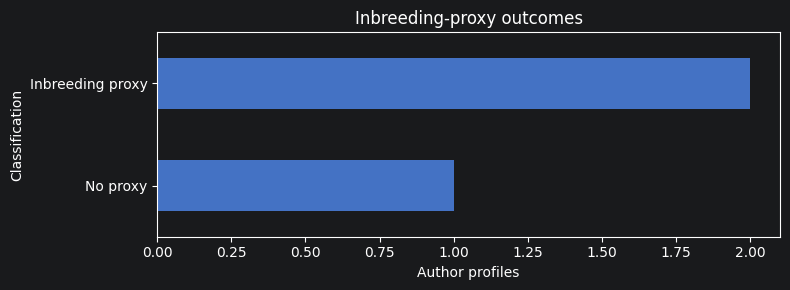

In [6]:
classification_counts = (
    proxy[IS_INBREEDING_PROXY]
    .map({True: "Inbreeding proxy", False: "No proxy"})
    .fillna("Unclassified")
    .value_counts()
    .sort_values()
)
ax = classification_counts.plot.barh(
    figsize=(8, max(3, 0.5 * len(classification_counts))),
    color="#4472C4",
)
ax.set(title="Inbreeding-proxy outcomes", xlabel="Author profiles", ylabel="Classification")
plt.tight_layout()
plt.show()

## 5. Author affiliation histories

These records are returned as `mobility_result.author_affiliations`; each author/institution row includes its mobility-derived history fields.

In [7]:
display(mobility_result.author_affiliations)

,sc_id,author_ids,name,affiliation_id,affiliation_id_parent,affiliation_name,affiliation_type,address,city,country,date_first,date_last,n_rows
0,990002,990000004,"do, john",9904000,NaN,NaN,NaN,NaN,None,None,2022-01-01,2022-01-01,1
1,990002,990000004,"do, john",9903000,NaN,NaN,NaN,NaN,None,None,2018-01-01,2020-06-15,3
2,990004,990000005,"lovelace, ada",9901000,NaN,NaN,NaN,NaN,None,None,2017-01-01,2022-01-01,3
3,990004,990000005,"lovelace, ada",9902000,NaN,NaN,NaN,NaN,None,None,2018-01-01,2018-01-01,1
4,990014,990000014,"lee, jamie",9905000,NaN,NaN,NaN,NaN,None,None,2020-01-01,2022-01-01,3


## 6. Author-article mobility and coaffiliation data

The output contains per-profile publication rows with the resolved and original affiliation identifiers. It remains available as `mobility_result.author_articles`.

In [8]:
display(mobility_result.author_articles)

,eid,author_ids,cover_date,author_afids,author_names,subject_areas,journal,city,country,synthetic_record,article_id,unmapped_id,affiliation_idx,n_authors_on_publication,article_general_asjc_subject_areas
0,SYN-MOB-ADA-001,990000005,2017-01-01,9901000,"[""Ada Lovelace"", ""Synthetic Collaborator""]","[{""area"": ""Software"", ""abbreviation"": ""COMP"", ""code"": 1712}]",Journal of Synthetic Ada Studies,Example City,Exampleland,True,21,9901001,{9901000: 0},2,{1700: 'General Computer Science'}
1,SYN-MOB-ADA-002,990000005,2018-01-01,9902000,"[""Ada Lovelace"", ""Synthetic Collaborator""]","[{""area"": ""Software"", ""abbreviation"": ""COMP"", ""code"": 1712}]",Journal of Synthetic Ada Studies,Example City,Exampleland,True,22,9902001,{9902000: 0},2,{1700: 'General Computer Science'}
2,SYN-MOB-JOHN-001,990000004,2018-01-01,9903000,"[""John Doe"", ""Synthetic Collaborator""]","[{""area"":""Chemistry"",""abbreviation"":""CHEM"",""code"":1600}]",Journal of Synthetic John Studies,Example City,Exampleland,True,24,9903001,{9903000: 0},2,{1600: 'General Chemistry'}
3,SYN-MOB-JOHN-002,990000004,2019-01-01,9903000,"[""John Doe"", ""Synthetic Collaborator""]","[{""area"":""Chemistry"",""abbreviation"":""CHEM"",""code"":1600}]",Journal of Synthetic John Studies,Example City,Exampleland,True,25,9903001,{9903000: 0},2,{1600: 'General Chemistry'}
4,SYN-MOB-JAMIE-001,990000014,2020-01-01,9905000,"[""Jamie Lee"", ""Synthetic Collaborator""]","[{""area"": ""Social Sciences"", ""abbreviation"": ""SOCI"", ""code"": 3300}]",Journal of Synthetic Jamie Studies,Example City,Exampleland,True,27,9905001,{9905000: 0},2,{3300: 'General Social Sciences'}
5,SYN-PUB-004,990000004,2020-06-15,9903000,"[""John Doe"", ""Casey Example"" ]","[{""area"":""Chemistry"",""abbreviation"":""CHEM"",""code"":1600}]",Journal of Fictional Chemistry,Example City,Exampleland,True,3,9903001,{9903000: 0},2,{1600: 'General Chemistry'}
6,SYN-PUB-005,990000005,2020-06-15,9901000,"[""Ada Lovelace"", ""Colleague 990000005""]","[{""area"": ""Software"", ""abbreviation"": ""COMP"", ""code"": 1712}]",Journal of Synthetic Software,Example City,Exampleland,True,4,9901001,{9901000: 0},2,{1700: 'General Computer Science'}
7,SYN-PUB-014,990000014,2021-06-15,9905000,"[""Jamie Lee"", ""Colleague 990000014""]","[{""area"": ""Social Sciences"", ""abbreviation"": ""SOCI"", ""code"": 3300}]",Journal of Synthetic Social Sciences,Example City,Exampleland,True,14,9905001,{9905000: 0},2,{3300: 'General Social Sciences'}
8,SYN-MOB-ADA-003,990000005,2022-01-01,9901000,"[""Ada Lovelace"", ""Synthetic Collaborator""]","[{""area"": ""Software"", ""abbreviation"": ""COMP"", ""code"": 1712}]",Journal of Synthetic Ada Studies,Example City,Exampleland,True,23,9901001,{9901000: 0},2,{1700: 'General Computer Science'}
9,SYN-MOB-JAMIE-002,990000014,2022-01-01,9905000,"[""Jamie Lee"", ""Synthetic Collaborator""]","[{""area"": ""Social Sciences"", ""abbreviation"": ""SOCI"", ""code"": 3300}]",Journal of Synthetic Jamie Studies,Example City,Exampleland,True,28,9905001,{9905000: 0},2,{3300: 'General Social Sciences'}


## Summary

This notebook loads mobility configuration and its validated inputs through the mobility package API, calls `compute_mobility(inputs, config)`, and displays the returned in-memory summary, affiliation history, and per-profile article tables. It does not assemble the low-level analyzer arguments, manually restore upstream metadata, or call the writer. Configured inputs are resolved from their canonical declarations; existing artifacts are reused without freshness detection.